# Python libraries for outlier detection and treatment
**Optional companion · 25–35 minutes of practice**

Keep the same restaurant story. We move from a transparent one-column rule to several-column
detectors, then to a reusable treatment transformer. Run this notebook independently of Notebook 01.
The lecture uses only a four-minute conceptual preview of these methods; do not attempt every cell live.

The NumPy, pandas, SciPy and scikit-learn sections run with `requirements.txt`.
The PyOD and Feature-engine sections are optional; install `requirements_optional.txt`
and restart the kernel first. They skip explicitly if unavailable. No automatic installations occur.

## Sources and data limitations
The tips data describes 244 meals recorded by one waiter at one restaurant over a few months.
Bill and tip amounts are US dollars; `size` is party size. It is a small historical convenience
sample, not a picture of current prices or a representative population. There are **no verified
outlier/error labels**. A statistical flag is not a proven error or fraud label.

- Data documentation and original reference: [R tips documentation](https://search.r-project.org/CRAN/refmans/reshape/html/tips.html).
  Bryant and Smith (1995), *Practical Data Analysis: Case Studies in Business Statistics*.
- CSV distribution: [seaborn-data tips.csv](https://github.com/mwaskom/seaborn-data/blob/master/tips.csv).
- [scikit-learn outlier guide](https://scikit-learn.org/stable/modules/outlier_detection.html).
- [IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)
  and [LocalOutlierFactor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html).
- [PyOD IForest](https://pyod.readthedocs.io/en/latest/_modules/pyod/models/iforest.html).
- [Feature-engine Winsorizer](https://feature-engine.trainindata.com/en/latest/user_guide/outliers/Winsorizer.html).

Only numeric restaurant context is used in detection. The demographic columns are not needed for this lesson.

In [1]:
from pathlib import Path
from io import StringIO
import sys, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# A small real dataset is embedded so this notebook also works alone in Colab.
# Prefer the bundled, unchanged CSV when the whole pack is extracted.
DATA_CSV = '"total_bill","tip","sex","smoker","day","time","size"\n16.99,1.01,"Female","No","Sun","Dinner",2\n10.34,1.66,"Male","No","Sun","Dinner",3\n21.01,3.5,"Male","No","Sun","Dinner",3\n23.68,3.31,"Male","No","Sun","Dinner",2\n24.59,3.61,"Female","No","Sun","Dinner",4\n25.29,4.71,"Male","No","Sun","Dinner",4\n8.77,2,"Male","No","Sun","Dinner",2\n26.88,3.12,"Male","No","Sun","Dinner",4\n15.04,1.96,"Male","No","Sun","Dinner",2\n14.78,3.23,"Male","No","Sun","Dinner",2\n10.27,1.71,"Male","No","Sun","Dinner",2\n35.26,5,"Female","No","Sun","Dinner",4\n15.42,1.57,"Male","No","Sun","Dinner",2\n18.43,3,"Male","No","Sun","Dinner",4\n14.83,3.02,"Female","No","Sun","Dinner",2\n21.58,3.92,"Male","No","Sun","Dinner",2\n10.33,1.67,"Female","No","Sun","Dinner",3\n16.29,3.71,"Male","No","Sun","Dinner",3\n16.97,3.5,"Female","No","Sun","Dinner",3\n20.65,3.35,"Male","No","Sat","Dinner",3\n17.92,4.08,"Male","No","Sat","Dinner",2\n20.29,2.75,"Female","No","Sat","Dinner",2\n15.77,2.23,"Female","No","Sat","Dinner",2\n39.42,7.58,"Male","No","Sat","Dinner",4\n19.82,3.18,"Male","No","Sat","Dinner",2\n17.81,2.34,"Male","No","Sat","Dinner",4\n13.37,2,"Male","No","Sat","Dinner",2\n12.69,2,"Male","No","Sat","Dinner",2\n21.7,4.3,"Male","No","Sat","Dinner",2\n19.65,3,"Female","No","Sat","Dinner",2\n9.55,1.45,"Male","No","Sat","Dinner",2\n18.35,2.5,"Male","No","Sat","Dinner",4\n15.06,3,"Female","No","Sat","Dinner",2\n20.69,2.45,"Female","No","Sat","Dinner",4\n17.78,3.27,"Male","No","Sat","Dinner",2\n24.06,3.6,"Male","No","Sat","Dinner",3\n16.31,2,"Male","No","Sat","Dinner",3\n16.93,3.07,"Female","No","Sat","Dinner",3\n18.69,2.31,"Male","No","Sat","Dinner",3\n31.27,5,"Male","No","Sat","Dinner",3\n16.04,2.24,"Male","No","Sat","Dinner",3\n17.46,2.54,"Male","No","Sun","Dinner",2\n13.94,3.06,"Male","No","Sun","Dinner",2\n9.68,1.32,"Male","No","Sun","Dinner",2\n30.4,5.6,"Male","No","Sun","Dinner",4\n18.29,3,"Male","No","Sun","Dinner",2\n22.23,5,"Male","No","Sun","Dinner",2\n32.4,6,"Male","No","Sun","Dinner",4\n28.55,2.05,"Male","No","Sun","Dinner",3\n18.04,3,"Male","No","Sun","Dinner",2\n12.54,2.5,"Male","No","Sun","Dinner",2\n10.29,2.6,"Female","No","Sun","Dinner",2\n34.81,5.2,"Female","No","Sun","Dinner",4\n9.94,1.56,"Male","No","Sun","Dinner",2\n25.56,4.34,"Male","No","Sun","Dinner",4\n19.49,3.51,"Male","No","Sun","Dinner",2\n38.01,3,"Male","Yes","Sat","Dinner",4\n26.41,1.5,"Female","No","Sat","Dinner",2\n11.24,1.76,"Male","Yes","Sat","Dinner",2\n48.27,6.73,"Male","No","Sat","Dinner",4\n20.29,3.21,"Male","Yes","Sat","Dinner",2\n13.81,2,"Male","Yes","Sat","Dinner",2\n11.02,1.98,"Male","Yes","Sat","Dinner",2\n18.29,3.76,"Male","Yes","Sat","Dinner",4\n17.59,2.64,"Male","No","Sat","Dinner",3\n20.08,3.15,"Male","No","Sat","Dinner",3\n16.45,2.47,"Female","No","Sat","Dinner",2\n3.07,1,"Female","Yes","Sat","Dinner",1\n20.23,2.01,"Male","No","Sat","Dinner",2\n15.01,2.09,"Male","Yes","Sat","Dinner",2\n12.02,1.97,"Male","No","Sat","Dinner",2\n17.07,3,"Female","No","Sat","Dinner",3\n26.86,3.14,"Female","Yes","Sat","Dinner",2\n25.28,5,"Female","Yes","Sat","Dinner",2\n14.73,2.2,"Female","No","Sat","Dinner",2\n10.51,1.25,"Male","No","Sat","Dinner",2\n17.92,3.08,"Male","Yes","Sat","Dinner",2\n27.2,4,"Male","No","Thur","Lunch",4\n22.76,3,"Male","No","Thur","Lunch",2\n17.29,2.71,"Male","No","Thur","Lunch",2\n19.44,3,"Male","Yes","Thur","Lunch",2\n16.66,3.4,"Male","No","Thur","Lunch",2\n10.07,1.83,"Female","No","Thur","Lunch",1\n32.68,5,"Male","Yes","Thur","Lunch",2\n15.98,2.03,"Male","No","Thur","Lunch",2\n34.83,5.17,"Female","No","Thur","Lunch",4\n13.03,2,"Male","No","Thur","Lunch",2\n18.28,4,"Male","No","Thur","Lunch",2\n24.71,5.85,"Male","No","Thur","Lunch",2\n21.16,3,"Male","No","Thur","Lunch",2\n28.97,3,"Male","Yes","Fri","Dinner",2\n22.49,3.5,"Male","No","Fri","Dinner",2\n5.75,1,"Female","Yes","Fri","Dinner",2\n16.32,4.3,"Female","Yes","Fri","Dinner",2\n22.75,3.25,"Female","No","Fri","Dinner",2\n40.17,4.73,"Male","Yes","Fri","Dinner",4\n27.28,4,"Male","Yes","Fri","Dinner",2\n12.03,1.5,"Male","Yes","Fri","Dinner",2\n21.01,3,"Male","Yes","Fri","Dinner",2\n12.46,1.5,"Male","No","Fri","Dinner",2\n11.35,2.5,"Female","Yes","Fri","Dinner",2\n15.38,3,"Female","Yes","Fri","Dinner",2\n44.3,2.5,"Female","Yes","Sat","Dinner",3\n22.42,3.48,"Female","Yes","Sat","Dinner",2\n20.92,4.08,"Female","No","Sat","Dinner",2\n15.36,1.64,"Male","Yes","Sat","Dinner",2\n20.49,4.06,"Male","Yes","Sat","Dinner",2\n25.21,4.29,"Male","Yes","Sat","Dinner",2\n18.24,3.76,"Male","No","Sat","Dinner",2\n14.31,4,"Female","Yes","Sat","Dinner",2\n14,3,"Male","No","Sat","Dinner",2\n7.25,1,"Female","No","Sat","Dinner",1\n38.07,4,"Male","No","Sun","Dinner",3\n23.95,2.55,"Male","No","Sun","Dinner",2\n25.71,4,"Female","No","Sun","Dinner",3\n17.31,3.5,"Female","No","Sun","Dinner",2\n29.93,5.07,"Male","No","Sun","Dinner",4\n10.65,1.5,"Female","No","Thur","Lunch",2\n12.43,1.8,"Female","No","Thur","Lunch",2\n24.08,2.92,"Female","No","Thur","Lunch",4\n11.69,2.31,"Male","No","Thur","Lunch",2\n13.42,1.68,"Female","No","Thur","Lunch",2\n14.26,2.5,"Male","No","Thur","Lunch",2\n15.95,2,"Male","No","Thur","Lunch",2\n12.48,2.52,"Female","No","Thur","Lunch",2\n29.8,4.2,"Female","No","Thur","Lunch",6\n8.52,1.48,"Male","No","Thur","Lunch",2\n14.52,2,"Female","No","Thur","Lunch",2\n11.38,2,"Female","No","Thur","Lunch",2\n22.82,2.18,"Male","No","Thur","Lunch",3\n19.08,1.5,"Male","No","Thur","Lunch",2\n20.27,2.83,"Female","No","Thur","Lunch",2\n11.17,1.5,"Female","No","Thur","Lunch",2\n12.26,2,"Female","No","Thur","Lunch",2\n18.26,3.25,"Female","No","Thur","Lunch",2\n8.51,1.25,"Female","No","Thur","Lunch",2\n10.33,2,"Female","No","Thur","Lunch",2\n14.15,2,"Female","No","Thur","Lunch",2\n16,2,"Male","Yes","Thur","Lunch",2\n13.16,2.75,"Female","No","Thur","Lunch",2\n17.47,3.5,"Female","No","Thur","Lunch",2\n34.3,6.7,"Male","No","Thur","Lunch",6\n41.19,5,"Male","No","Thur","Lunch",5\n27.05,5,"Female","No","Thur","Lunch",6\n16.43,2.3,"Female","No","Thur","Lunch",2\n8.35,1.5,"Female","No","Thur","Lunch",2\n18.64,1.36,"Female","No","Thur","Lunch",3\n11.87,1.63,"Female","No","Thur","Lunch",2\n9.78,1.73,"Male","No","Thur","Lunch",2\n7.51,2,"Male","No","Thur","Lunch",2\n14.07,2.5,"Male","No","Sun","Dinner",2\n13.13,2,"Male","No","Sun","Dinner",2\n17.26,2.74,"Male","No","Sun","Dinner",3\n24.55,2,"Male","No","Sun","Dinner",4\n19.77,2,"Male","No","Sun","Dinner",4\n29.85,5.14,"Female","No","Sun","Dinner",5\n48.17,5,"Male","No","Sun","Dinner",6\n25,3.75,"Female","No","Sun","Dinner",4\n13.39,2.61,"Female","No","Sun","Dinner",2\n16.49,2,"Male","No","Sun","Dinner",4\n21.5,3.5,"Male","No","Sun","Dinner",4\n12.66,2.5,"Male","No","Sun","Dinner",2\n16.21,2,"Female","No","Sun","Dinner",3\n13.81,2,"Male","No","Sun","Dinner",2\n17.51,3,"Female","Yes","Sun","Dinner",2\n24.52,3.48,"Male","No","Sun","Dinner",3\n20.76,2.24,"Male","No","Sun","Dinner",2\n31.71,4.5,"Male","No","Sun","Dinner",4\n10.59,1.61,"Female","Yes","Sat","Dinner",2\n10.63,2,"Female","Yes","Sat","Dinner",2\n50.81,10,"Male","Yes","Sat","Dinner",3\n15.81,3.16,"Male","Yes","Sat","Dinner",2\n7.25,5.15,"Male","Yes","Sun","Dinner",2\n31.85,3.18,"Male","Yes","Sun","Dinner",2\n16.82,4,"Male","Yes","Sun","Dinner",2\n32.9,3.11,"Male","Yes","Sun","Dinner",2\n17.89,2,"Male","Yes","Sun","Dinner",2\n14.48,2,"Male","Yes","Sun","Dinner",2\n9.6,4,"Female","Yes","Sun","Dinner",2\n34.63,3.55,"Male","Yes","Sun","Dinner",2\n34.65,3.68,"Male","Yes","Sun","Dinner",4\n23.33,5.65,"Male","Yes","Sun","Dinner",2\n45.35,3.5,"Male","Yes","Sun","Dinner",3\n23.17,6.5,"Male","Yes","Sun","Dinner",4\n40.55,3,"Male","Yes","Sun","Dinner",2\n20.69,5,"Male","No","Sun","Dinner",5\n20.9,3.5,"Female","Yes","Sun","Dinner",3\n30.46,2,"Male","Yes","Sun","Dinner",5\n18.15,3.5,"Female","Yes","Sun","Dinner",3\n23.1,4,"Male","Yes","Sun","Dinner",3\n15.69,1.5,"Male","Yes","Sun","Dinner",2\n19.81,4.19,"Female","Yes","Thur","Lunch",2\n28.44,2.56,"Male","Yes","Thur","Lunch",2\n15.48,2.02,"Male","Yes","Thur","Lunch",2\n16.58,4,"Male","Yes","Thur","Lunch",2\n7.56,1.44,"Male","No","Thur","Lunch",2\n10.34,2,"Male","Yes","Thur","Lunch",2\n43.11,5,"Female","Yes","Thur","Lunch",4\n13,2,"Female","Yes","Thur","Lunch",2\n13.51,2,"Male","Yes","Thur","Lunch",2\n18.71,4,"Male","Yes","Thur","Lunch",3\n12.74,2.01,"Female","Yes","Thur","Lunch",2\n13,2,"Female","Yes","Thur","Lunch",2\n16.4,2.5,"Female","Yes","Thur","Lunch",2\n20.53,4,"Male","Yes","Thur","Lunch",4\n16.47,3.23,"Female","Yes","Thur","Lunch",3\n26.59,3.41,"Male","Yes","Sat","Dinner",3\n38.73,3,"Male","Yes","Sat","Dinner",4\n24.27,2.03,"Male","Yes","Sat","Dinner",2\n12.76,2.23,"Female","Yes","Sat","Dinner",2\n30.06,2,"Male","Yes","Sat","Dinner",3\n25.89,5.16,"Male","Yes","Sat","Dinner",4\n48.33,9,"Male","No","Sat","Dinner",4\n13.27,2.5,"Female","Yes","Sat","Dinner",2\n28.17,6.5,"Female","Yes","Sat","Dinner",3\n12.9,1.1,"Female","Yes","Sat","Dinner",2\n28.15,3,"Male","Yes","Sat","Dinner",5\n11.59,1.5,"Male","Yes","Sat","Dinner",2\n7.74,1.44,"Male","Yes","Sat","Dinner",2\n30.14,3.09,"Female","Yes","Sat","Dinner",4\n12.16,2.2,"Male","Yes","Fri","Lunch",2\n13.42,3.48,"Female","Yes","Fri","Lunch",2\n8.58,1.92,"Male","Yes","Fri","Lunch",1\n15.98,3,"Female","No","Fri","Lunch",3\n13.42,1.58,"Male","Yes","Fri","Lunch",2\n16.27,2.5,"Female","Yes","Fri","Lunch",2\n10.09,2,"Female","Yes","Fri","Lunch",2\n20.45,3,"Male","No","Sat","Dinner",4\n13.28,2.72,"Male","No","Sat","Dinner",2\n22.12,2.88,"Female","Yes","Sat","Dinner",2\n24.01,2,"Male","Yes","Sat","Dinner",4\n15.69,3,"Male","Yes","Sat","Dinner",3\n11.61,3.39,"Male","No","Sat","Dinner",2\n10.77,1.47,"Male","No","Sat","Dinner",2\n15.53,3,"Male","Yes","Sat","Dinner",2\n10.07,1.25,"Male","No","Sat","Dinner",2\n12.6,1,"Male","Yes","Sat","Dinner",2\n32.83,1.17,"Male","Yes","Sat","Dinner",2\n35.83,4.67,"Female","No","Sat","Dinner",3\n29.03,5.92,"Male","No","Sat","Dinner",3\n27.18,2,"Female","Yes","Sat","Dinner",2\n22.67,2,"Male","Yes","Sat","Dinner",2\n17.82,1.75,"Male","No","Sat","Dinner",2\n18.78,3,"Female","No","Thur","Dinner",2\n'
local = Path('data/tips.csv')
df = pd.read_csv(local) if local.exists() else pd.read_csv(StringIO(DATA_CSV))
df.index.name = 'row_id'  # zero-based row number, not a receipt identifier
assert df.shape == (244, 7)
assert df[['total_bill', 'tip', 'size']].notna().all().all()
assert (df['total_bill'] > 0).all() and (df['size'] >= 1).all()
original = df.copy(deep=True)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Python:', platform.python_version())
print({p: importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','scikit-learn','scipy']})
print('Rows:', len(df), '| Missing values:', int(df.isna().sum().sum()))

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler
from scipy import stats
train, test = train_test_split(df, test_size=.25, random_state=42)
features = ['total_bill','size']
X_train, X_test = train[features].copy(), test[features].copy()
print('Fit on',len(X_train),'reference meals; score',len(X_test),'held-out meals.')

Python: 3.12.14
{'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0', 'scipy': '1.17.0'}
Rows: 244 | Missing values: 0
Fit on 183 reference meals; score 61 held-out meals.


## 1 · NumPy and pandas · transparent IQR rules
Best starting point when a small number of numeric columns and clear units matter.
Easy to explain and audit, but independent column rules miss unusual combinations.

In [2]:
q1, q3 = X_train['total_bill'].quantile([.25,.75])
lo, hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
iqr_test = (X_test['total_bill']<lo)|(X_test['total_bill']>hi)
print('Held-out IQR review candidates:',int(iqr_test.sum()))

Held-out IQR review candidates: 2


## 2 · SciPy · z scores and robust spread
Use SciPy's statistical building blocks, but keep the meaning of the rule visible.
The held-out z scores below use the **training mean and SD**. Calling `stats.zscore(X_test)`
would incorrectly redefine the reference on the test batch. Bills are skewed, so |z| > 3
is only a comparison rule here. `scale='normal'` rescales MAD for a normal-reference SD estimate.

The API is `scipy.stats.zscore()`. With a ±3 threshold, flag scores below -3 or above +3.
The code explicitly sets `ddof=0` to match its training SD calculation.


In [3]:
mean_train = X_train['total_bill'].mean()
sd_train = X_train['total_bill'].std(ddof=0)
mad_sd_train = stats.median_abs_deviation(X_train['total_bill'], scale='normal')
if sd_train == 0 or mad_sd_train == 0:
    raise ValueError('Undefined standardized score; investigate repeated/constant values.')
z_test = (X_test['total_bill']-mean_train)/sd_train
robust_z_test = (X_test['total_bill']-X_train['total_bill'].median())/mad_sd_train
print('Training z-score demonstration (first five):',
      np.round(stats.zscore(X_train['total_bill'], ddof=0)[:5],2))
print('Held-out |z| > 3:',int((z_test.abs()>3).sum()))
print('Held-out |modified z| > 3.5:',int((robust_z_test.abs()>3.5).sum()))

Training z-score demonstration (first five): [-0.33  0.35 -0.45 -0.    0.07]
Held-out |z| > 3: 1
Held-out |modified z| > 3.5: 1


## 3 · scikit-learn Isolation Forest · unusual combinations
Imagine repeatedly splitting meals by randomly chosen bill or party-size cutoffs.
An isolated combination often takes fewer splits to separate. That gives an anomaly score.
Use bill and party size, not the tip target. We do not claim any candidate is an error.

`contamination=0.05` is a **demonstration threshold assumption** based on the training score
distribution; it does not discover that 5% of meals are truly wrong. The fraction flagged on
held-out data may differ. For scikit-learn, labels −1 mean unusual and +1 mean usual;
lower `decision_function` means more unusual. Scores are not probabilities.

Held-out Isolation Forest candidates: 4


,total_bill,size,decision_score,flag
row_id,,,,
67,3.07,1,-0.086384,True
156,48.17,6,-0.085046,True
82,10.07,1,-0.020927,True
142,41.19,5,-0.014563,True
16,10.33,3,0.006514,False
155,29.85,5,0.038969,False
197,43.11,4,0.049504,False
112,38.07,3,0.075243,False


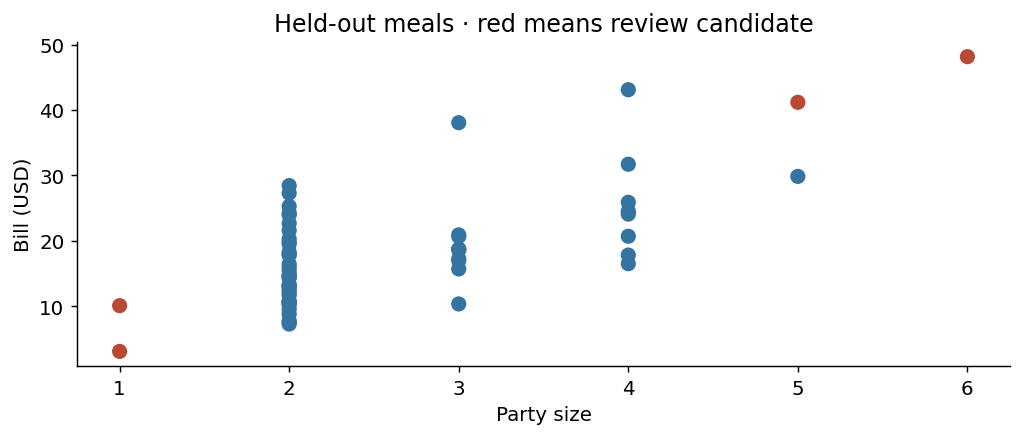

In [4]:
forest = IsolationForest(n_estimators=200, contamination=.05, random_state=42)
forest.fit(X_train)
if_label = forest.predict(X_test)
if_score = forest.decision_function(X_test)
if_flag = if_label == -1
print('Held-out Isolation Forest candidates:',int(if_flag.sum()))
display(X_test.assign(decision_score=if_score, flag=if_flag)
        .sort_values('decision_score').head(8))
fig, ax = plt.subplots(figsize=(8,3.5))
ax.scatter(X_test['size'], X_test['total_bill'], c=np.where(if_flag,'#b84935','#3574a1'), s=55)
ax.set(xlabel='Party size',ylabel='Bill (USD)',title='Held-out meals · red means review candidate')
plt.tight_layout(); plt.show()

## 4 · Local Outlier Factor · compare with nearby meals
LOF asks whether a meal is less densely surrounded than its neighbours. Distances depend on units,
so scale bill and party size using **training rows only**. RobustScaler uses median and IQR:
it changes scale but **does not remove outliers or make bad values correct**.
Party size is discrete; distances are an approximation, and neighbour choice affects results.

Two scikit-learn modes matter:
- Default `novelty=False`: use `fit_predict` on the reference batch to find outliers in it.
- `novelty=True`: fit on the reference and call `predict` only on unseen rows. This is a novelty-style
  API; a carefully reviewed mostly normal reference is preferable. Here the reference is unverified.

These modes do not promise identical decisions. Do not call a novelty-mode predictor on its training rows.

In [5]:
scaler = RobustScaler().fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)
lof_batch = LocalOutlierFactor(n_neighbors=20, contamination=.05)
batch_labels = lof_batch.fit_predict(Z_train)
print('Training-batch LOF candidates:',int((batch_labels==-1).sum()))
lof_new = LocalOutlierFactor(n_neighbors=20, contamination=.05, novelty=True)
lof_new.fit(Z_train)
lof_label_test = lof_new.predict(Z_test)  # unseen rows only
print('Held-out novelty-mode LOF candidates:',int((lof_label_test==-1).sum()))

Training-batch LOF candidates: 10
Held-out novelty-mode LOF candidates: 4


## 5 · Agreement is a review aid, not accuracy
Compare methods on the **same held-out rows**. No true outlier labels are available, so we cannot
report detection accuracy, precision, recall or ROC AUC. Agreement is not ground truth and majority
voting is not proof. Read flagged rows, check receipts, assess review cost and examine group impacts.
Sensitivity to contamination or neighbour count should be checked on training/validation data.

In [6]:
flags = pd.DataFrame({'IQR bill':iqr_test, 'Isolation Forest':if_flag,
                       'LOF novelty':lof_label_test==-1}, index=X_test.index)
display(flags.sum().to_frame('held_out_flags'))
agreement = pd.DataFrame(index=flags.columns, columns=flags.columns, dtype=float)
for a in flags:
    for b in flags:
        union = (flags[a]|flags[b]).sum()
        agreement.loc[a,b] = (flags[a]&flags[b]).sum()/union if union else np.nan
display(agreement.round(2))  # Jaccard = intersection / union of review sets
display(test.loc[flags.any(axis=1), ['total_bill','size','tip','day','time']]
        .join(flags).sort_values('total_bill', ascending=False))

,held_out_flags
IQR bill,2
Isolation Forest,4
LOF novelty,4


,IQR bill,Isolation Forest,LOF novelty
IQR bill,1.0,0.2,0.2
Isolation Forest,0.2,1.0,0.6
LOF novelty,0.2,0.6,1.0


,total_bill,size,tip,day,time,IQR bill,Isolation Forest,LOF novelty
row_id,,,,,,,,
156,48.17,6,5.00,Sun,Dinner,True,True,True
197,43.11,4,5.00,Thur,Lunch,True,False,False
142,41.19,5,5.00,Thur,Lunch,False,True,False
16,10.33,3,1.67,Sun,Dinner,False,False,True
82,10.07,1,1.83,Thur,Lunch,False,True,True
67,3.07,1,1.00,Sat,Dinner,False,True,True


## 6 · Optional PyOD · a common anomaly-detection interface
PyOD wraps many detectors behind a similar API. Here we use its Isolation Forest wrapper.
**Convention differs:** PyOD labels 1 = outlier and 0 = inlier; larger `decision_function`
values mean more abnormal. Do not compare numeric score scales across packages or treat them as probabilities.

This extension was syntax-checked but not executed in the preparation environment because PyOD
was unavailable. Install optional dependencies and run this section before teaching it.

In [7]:
try:
    from pyod.models.iforest import IForest
except ImportError:
    print('SKIPPED PyOD: install requirements_optional.txt and restart the kernel.')
else:
    pyod_model = IForest(n_estimators=200, contamination=.05, random_state=42)
    pyod_model.fit(X_train.to_numpy())
    pyod_labels = pyod_model.predict(X_test.to_numpy())
    pyod_scores = pyod_model.decision_function(X_test.to_numpy())
    display(X_test.assign(pyod_score=pyod_scores, pyod_flag=pyod_labels==1)
            .sort_values('pyod_score', ascending=False).head(8))
    print('PyOD candidates:',int((pyod_labels==1).sum()))

SKIPPED PyOD: install requirements_optional.txt and restart the kernel.


## 7 · Optional Feature-engine · a fitted capping transformer
`Winsorizer` learns limits during `fit` and applies them during `transform`, making it useful in
an sklearn pipeline. This example explicitly requests IQR fences at 1.5 IQR on the bill feature.
Fit on training rows; transform both training and held-out rows with those same fitted limits.
Feature-engine also supports percentile capping, which has a different rule from IQR capping.
Neither rule is automatic permission to alter data.

This extension was syntax-checked but not executed in the preparation environment because
Feature-engine was unavailable. Install optional dependencies and run it before teaching it.

In [8]:
try:
    from feature_engine.outliers import Winsorizer
except ImportError:
    print('SKIPPED Feature-engine: install requirements_optional.txt and restart the kernel.')
else:
    capper = Winsorizer(capping_method='iqr', tail='both', fold=1.5,
                        variables=['total_bill'])
    capper.fit(X_train)
    capped_train = capper.transform(X_train)
    capped_test = capper.transform(X_test)
    print('Fitted lower limits:', capper.left_tail_caps_)
    print('Fitted upper limits:', capper.right_tail_caps_)
    expected = X_test['total_bill'].clip(lower=lo,upper=hi)
    assert np.allclose(capped_test['total_bill'], expected)
    print('Held-out bills capped:', int((capped_test['total_bill']!=X_test['total_bill']).sum()))

SKIPPED Feature-engine: install requirements_optional.txt and restart the kernel.


## Choosing a first tool
| Need | Start with | Watch for |
|---|---|---|
| Explain one numeric rule | pandas / NumPy IQR | Skew, group differences, small samples |
| Statistical building blocks | SciPy | Reference statistics and score assumptions |
| Several numeric features | sklearn IsolationForest | Feature choice and threshold assumptions |
| Local neighbourhood differences | sklearn LOF | Scaling, neighbours, batch versus novelty API |
| Explore many detectors | PyOD | Label/score conventions and validation |
| Reusable capping in a pipeline | Feature-engine | Fit only on training folds |

Do not start this beginner class with One-Class SVM, DBSCAN, autoencoders or extensive parameter
tuning. They can be follow-up topics after students understand reference distributions and validation.

### Practice
On training rows, try contamination 0.02 and 0.10. Inspect which meals change status.
Repeat LOF with 10 and 30 neighbours. Do not pick the result with the fewest flags as the winner.
Write down which errors your restaurant wants to catch and how you would verify the candidates.